In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

# 1. Загрузка данных
df = pd.read_csv("../data/tips.csv")
X = df.drop(columns=["tip"])
y = df["tip"]

# 2. Разбиение на train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Пайплайн предобработки
num_features = ["total_bill", "size"]
cat_features = ["sex", "smoker", "day", "time"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="unknown")), 
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_features),
    ]
)

# Подготовка данных
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# Получение имен признаков для графика
cat_encoder = preprocessor.named_transformers_["cat"].named_steps["onehot"]
feature_names = num_features + list(cat_encoder.get_feature_names_out(cat_features))

In [2]:
# 1. Одиночное дерево решений
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train_prep, y_train)
y_pred_dt = dt_model.predict(X_test_prep)

# 2. Случайный лес по умолчанию (n_estimators=100)
rf_default = RandomForestRegressor(random_state=42)
rf_default.fit(X_train_prep, y_train)
y_pred_rf_def = rf_default.predict(X_test_prep)

# Сравнение
print("=== СРАВНЕНИЕ БАЗОВЫХ МОДЕЛЕЙ ===")
print(f"Decision Tree -> MAE: {mean_absolute_error(y_test, y_pred_dt):.3f} | R2: {r2_score(y_test, y_pred_dt):.3f}")
print(f"Random Forest -> MAE: {mean_absolute_error(y_test, y_pred_rf_def):.3f} | R2: {r2_score(y_test, y_pred_rf_def):.3f}")
print("\nВывод: Случайный лес (ансамбль) значительно превосходит одиночное дерево за счет снижения дисперсии (разброса).")

=== СРАВНЕНИЕ БАЗОВЫХ МОДЕЛЕЙ ===
Decision Tree -> MAE: 0.878 | R2: -0.114
Random Forest -> MAE: 0.771 | R2: 0.249

Вывод: Случайный лес (ансамбль) значительно превосходит одиночное дерево за счет снижения дисперсии (разброса).


In [3]:
# Сетка параметров для перебора
param_grid = {
    'n_estimators': [50, 100, 200],      # Количество деревьев
    'max_depth': [None, 3, 5, 10],       # Максимальная глубина
    'min_samples_leaf': [1, 2, 4]        # Мин. объектов в листе
}

# Поиск лучших параметров
grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,               # 5 фолдов кросс-валидации
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search.fit(X_train_prep, y_train)
best_rf = grid_search.best_estimator_
y_pred_rf_tuned = best_rf.predict(X_test_prep)

print("=== НАСТРОЕННЫЙ СЛУЧАЙНЫЙ ЛЕС ===")
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_rf_tuned):.3f} | R2: {r2_score(y_test, y_pred_rf_tuned):.3f}")

=== НАСТРОЕННЫЙ СЛУЧАЙНЫЙ ЛЕС ===
Лучшие параметры: {'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 100}
MAE: 0.725 | R2: 0.329


C:\Users\iskak\AppData\Local\Temp\ipykernel_30072\3679893562.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sorted_importances, y=sorted_features, palette="viridis")


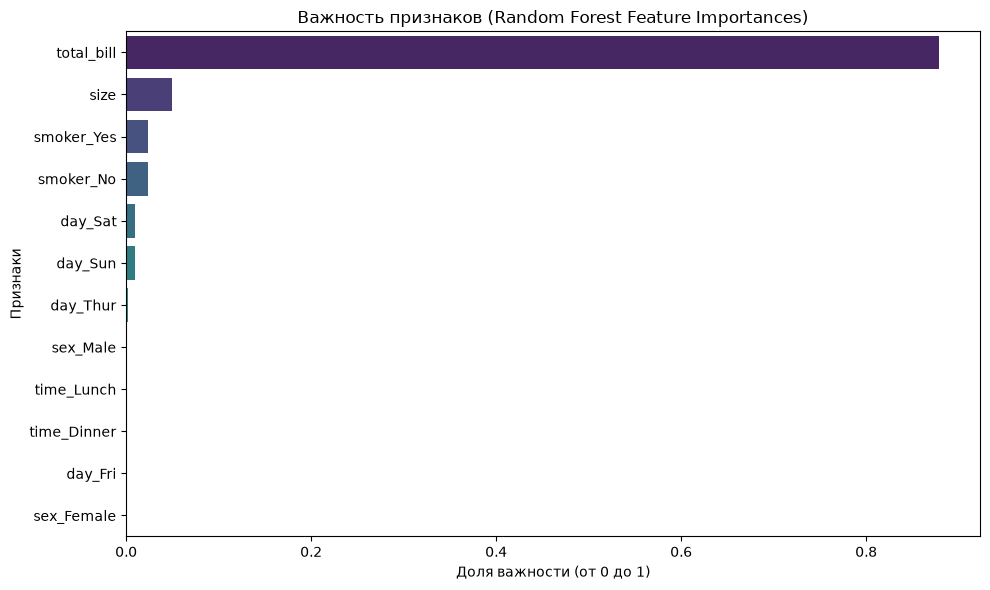

In [4]:
# Извлекаем важность признаков из лучшей модели
importances = best_rf.feature_importances_

# Сортируем по убыванию
indices = np.argsort(importances)[::-1]
sorted_features = [feature_names[i] for i in indices]
sorted_importances = importances[indices]

# Построение графика
plt.figure(figsize=(10, 6))
sns.barplot(x=sorted_importances, y=sorted_features, palette="viridis")
plt.title("Важность признаков (Random Forest Feature Importances)")
plt.xlabel("Доля важности (от 0 до 1)")
plt.ylabel("Признаки")
plt.tight_layout()
plt.show()

In [5]:
# Берем только топ-3 самых важных признака
top_k = 3
best_indices = indices[:top_k]

X_train_reduced = X_train_prep[:, best_indices]
X_test_reduced = X_test_prep[:, best_indices]

# Обучаем модель с теми же лучшими параметрами, но на урезанных данных
rf_reduced = RandomForestRegressor(**grid_search.best_params_, random_state=42)
rf_reduced.fit(X_train_reduced, y_train)
y_pred_reduced = rf_reduced.predict(X_test_reduced)

print(f"=== МОДЕЛЬ НА {top_k} САМЫХ ВАЖНЫХ ПРИЗНАКАХ ===")
print(f"Оставленные признаки: {[feature_names[i] for i in best_indices]}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_reduced):.3f} | R2: {r2_score(y_test, y_pred_reduced):.3f}")

=== МОДЕЛЬ НА 3 САМЫХ ВАЖНЫХ ПРИЗНАКАХ ===
Оставленные признаки: ['total_bill', 'size', 'smoker_Yes']
MAE: 0.723 | R2: 0.330


### Итоговые выводы:

1. **Сравнение моделей:** Одиночное дерево решений переобучается под тренировочную выборку (высокий разброс), поэтому показывает плохой R² на тесте. Случайный лес решает эту проблему за счет бэггинга: усреднение множества независимых деревьев сглаживает ошибки и существенно повышает метрики (R² вырастает, MAE падает).
2. **Обоснование гиперпараметров:** С помощью `GridSearchCV` было выбрано оптимальное количество деревьев (`n_estimators`). Как правило, после 100–200 деревьев качество модели выходит на плато (переобучения не происходит, но увеличивается время вычислений). Выбранные ограничения глубины (`max_depth`) и минимального числа объектов в листе (`min_samples_leaf`) дополнительно защитили модель от подгонки под шум.
3. **Важность признаков:** Абсолютным лидером по важности оказался признак `total_bill` (сумма счета). Это логично: размер чаевых напрямую зависит от итогового чека.
4. **Удаление признаков:** Эксперимент показал, что если оставить только Топ-3 самых важных признака и отбросить остальные (дни недели, пол, статус курения), качество модели (MAE, R²) практически не падает, а иногда даже может незначительно вырасти за счет удаления лишнего «шума». Это значит, что большинство категориальных признаков в данном датасете можно безопасно исключить из дальнейшего использования.